# Lab 10 — Image Segmentation and Feature Extraction
**Course:** ARTI404 – Image Processing  
**College of Computer Science and Information Technology**  
**Imam Abdulrahman Bin Faisal University**

This notebook contains:
1. The two examples from the lab manual (Canny Edge Detection, Harris Corner Detection).
2. The assessment task (Otsu's thresholding).



Ali Jafar Altaweel

2240006456

7MA2

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data   # provides sample images (camera, checkerboard, coins, ...)

# Make plots show inside the notebook
%matplotlib inline

## Task 1 — Canny Edge Detection

An **edge** is where brightness changes sharply. Canny (1986) finds edges in 5 steps: Gaussian blur → gradients → non-maximum suppression (thin the edges) → double thresholding → hysteresis (keep weak edges only if they connect to strong ones).

`cv2.Canny(img, T_low, T_high)`:
- `T_low` = lower threshold (weak edges)
- `T_high` = upper threshold (strong edges)
- Rule of thumb: `T_high ≈ 2×T_low` or `3×T_low`.

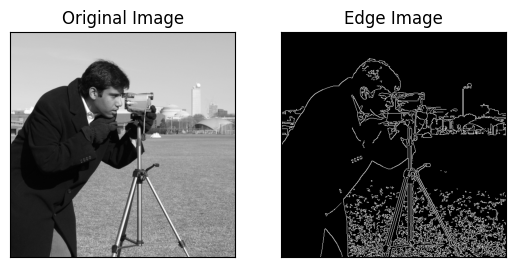

In [2]:
# --- Code from the lab manual ---
img = data.camera()                                  

edges = cv2.Canny(img, 100, 200)

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(edges, cmap='gray')
plt.title('Edge Image'), plt.xticks([]), plt.yticks([])
plt.show()

## Task 2 — Harris Corner Detection

A **corner** is a point where the image changes in *two* different directions — which makes corners highly distinctive (useful for matching, tracking, camera calibration).



- Large positive `R` → corner
- Large negative `R` → edge
- Small `R` → flat region

Parameters: `blockSize` (window size), `ksize` (Sobel kernel size), `k` (sensitivity, typically 0.04–0.06).

> **Note:** OpenCV uses BGR order, so `(0, 0, 255)` is red.

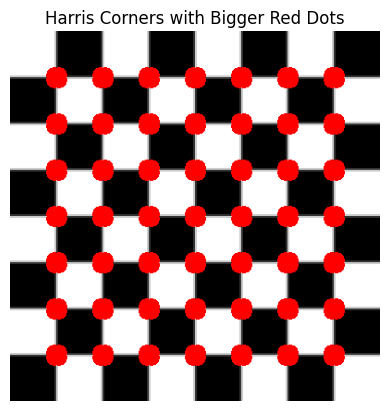

In [3]:
# --- Code from the lab manual ---
board = data.checkerboard()                        
image = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
image = cv2.resize(image, (400, 400), interpolation=cv2.INTER_NEAREST)

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray)

# Harris Corner Detection
harris = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)
harris = cv2.dilate(harris, None)   # to mark corners more clearly

# Threshold for detecting strong corners
threshold = 0.01 * harris.max()
corner_coords = np.argwhere(harris > threshold)

# Draw larger red dots (radius = 7)
for y, x in corner_coords:
    cv2.circle(image, (x, y), radius=7, color=(0, 0, 255), thickness=-1)  # -1 = filled

# Display
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Harris Corners with Bigger Red Dots')
plt.axis('off')
plt.show()

## Simple (Global) Binary Thresholding
The most basic segmentation: pick a fixed threshold `T` and turn every pixel above it white, below it black.

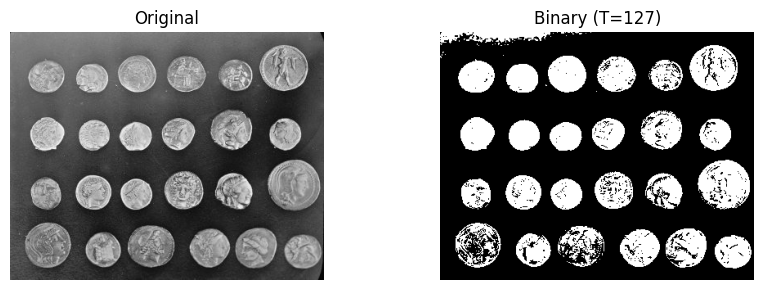

(None, None)

In [4]:
img = data.coins()

T = 127
_, binary = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary, cmap='gray'), plt.title(f'Binary (T={T})'), plt.axis('off')
plt.tight_layout(), plt.show()

## Q1 — Otsu's Thresholding (Assessment Task)
Otsu picks `T` **automatically** by maximizing the between-class variance — assumes the histogram has two peaks (foreground + background).

show the original image, its histogram, and the thresholded image.

### Q1 Solution – Otsu's thresholding on the coins image

image: (303, 384) uint8   min: 1   max: 252
Otsu threshold found by OpenCV: T = 107.0
white (coins) pixels: 38.8%


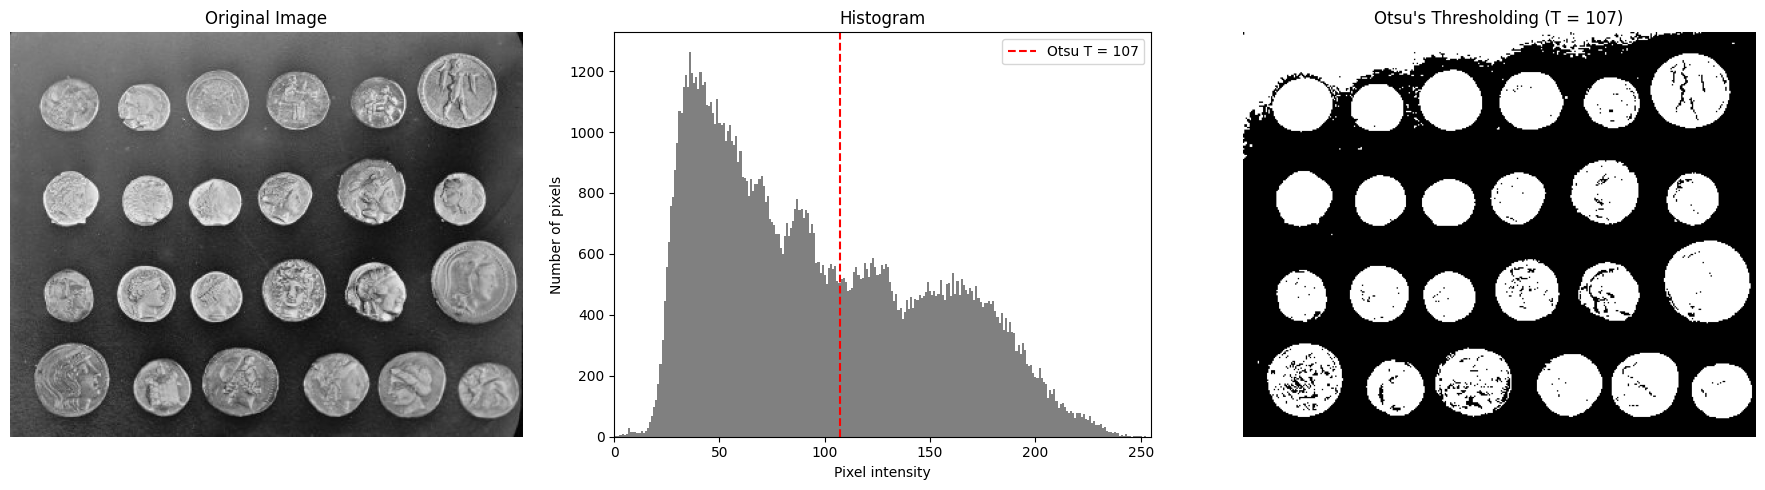

In [5]:
# 1. Load the coins image used in the lab (grayscale)
img = data.coins()
print("image:", img.shape, img.dtype, "  min:", img.min(), "  max:", img.max())

# 2. Otsu's thresholding: the threshold argument (0) is ignored, OpenCV finds T by itself and returns it
otsu_t, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold found by OpenCV: T =", otsu_t)
print(f"white (coins) pixels: {(otsu > 0).mean() * 100:.1f}%")

# 3. Histogram of the image
hist = cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()

# 4. Display the original image, its histogram (with the Otsu threshold) and the thresholded image
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1), plt.imshow(img, 'gray'), plt.title('Original Image'), plt.axis('off')
plt.subplot(1, 3, 2), plt.bar(np.arange(256), hist, width=1, color='gray')
plt.axvline(otsu_t, color='r', linestyle='--', label=f'Otsu T = {otsu_t:.0f}')
plt.xlim([0, 255]), plt.xlabel('Pixel intensity'), plt.ylabel('Number of pixels')
plt.title('Histogram'), plt.legend()
plt.subplot(1, 3, 3), plt.imshow(otsu, 'gray'), plt.title(f"Otsu's Thresholding (T = {otsu_t:.0f})"), plt.axis('off')
plt.tight_layout()
plt.show()

### Q1 Solution – Checking the threshold by computing Otsu's method by hand

Otsu threshold computed by hand: T = 107   (OpenCV: 107 )
class 0 (background): weight = 0.612, mean = 60.3
class 1 (coins):      weight = 0.388, mean = 154.6
max between-class variance = 2115.1, total variance = 2796.3, separability = 0.756
hand-made binary image is identical to OpenCV's: True


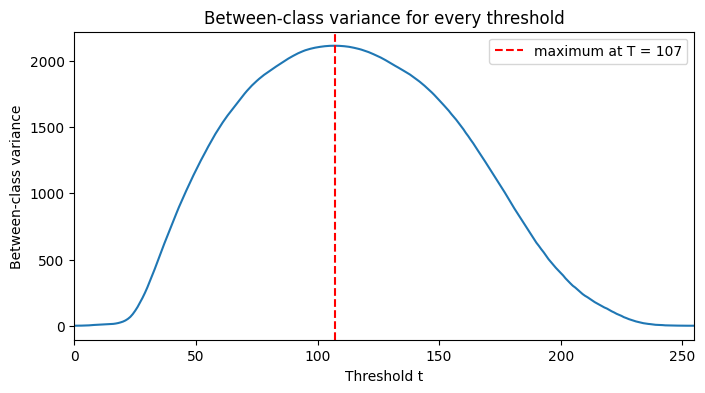

In [6]:
# Otsu tries every threshold t and picks the one that maximizes the between-class variance
#   sigma_B^2(t) = w0 * w1 * (mu0 - mu1)^2   (class 0 = pixels <= t, class 1 = pixels > t)
p = hist / hist.sum()                      # probability of each gray level
levels = np.arange(256)
w0 = np.cumsum(p)                          # weight of class 0 for every t
w1 = 1 - w0                                # weight of class 1
cum_mean = np.cumsum(p * levels)
mu_T = cum_mean[-1]                        # mean of the whole image
with np.errstate(divide='ignore', invalid='ignore'):
    mu0 = cum_mean / w0                    # mean of class 0
    mu1 = (mu_T - cum_mean) / w1           # mean of class 1
    sigma_b = np.nan_to_num(w0 * w1 * (mu0 - mu1) ** 2)

t_best = int(np.argmax(sigma_b))
sigma_total = np.sum(p * (levels - mu_T) ** 2)
print("Otsu threshold computed by hand: T =", t_best, "  (OpenCV:", int(otsu_t), ")")
print(f"class 0 (background): weight = {w0[t_best]:.3f}, mean = {mu0[t_best]:.1f}")
print(f"class 1 (coins):      weight = {w1[t_best]:.3f}, mean = {mu1[t_best]:.1f}")
print(f"max between-class variance = {sigma_b[t_best]:.1f}, total variance = {sigma_total:.1f}, "
      f"separability = {sigma_b[t_best] / sigma_total:.3f}")

# the same rule applied by hand gives the same binary image
manual = np.where(img > t_best, 255, 0).astype(np.uint8)
print("hand-made binary image is identical to OpenCV's:", np.array_equal(manual, otsu))

plt.figure(figsize=(8, 4))
plt.plot(levels, sigma_b)
plt.axvline(t_best, color='r', linestyle='--', label=f'maximum at T = {t_best}')
plt.xlim([0, 255]), plt.xlabel('Threshold t'), plt.ylabel('Between-class variance')
plt.title('Between-class variance for every threshold'), plt.legend()
plt.show()

### Q1 Solution – Comparing Otsu with the fixed threshold and with Otsu after Gaussian filtering

Fixed threshold  T =   127   white pixels:  29.6%   white objects: 119
Otsu             T =   107   white pixels:  38.8%   white objects:  96
Gaussian + Otsu  T =   104   white pixels:  41.3%   white objects:  34


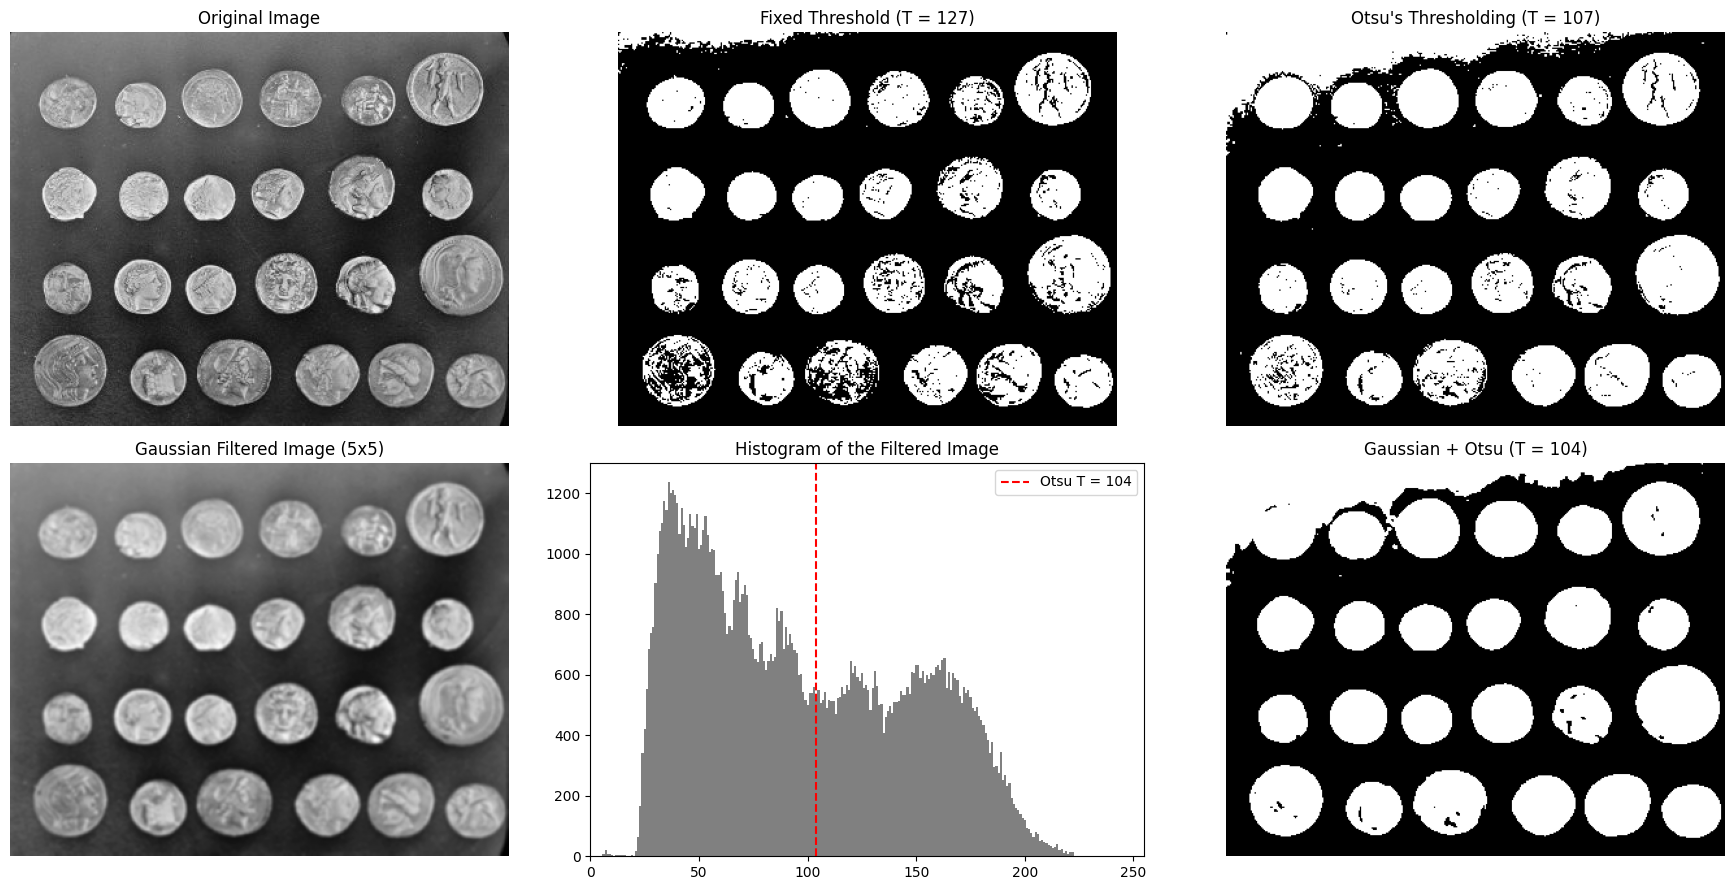

In [7]:
# the simple threshold of the lab (T = 127) and Otsu after a 5x5 Gaussian blur, which removes the noise first
_, fixed = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
blur = cv2.GaussianBlur(img, (5, 5), 0)
blur_t, otsu_blur = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

def count_objects(b):          # white connected regions
    return cv2.connectedComponents(b)[0] - 1

for name, t, b in (("Fixed threshold", 127, fixed), ("Otsu", otsu_t, otsu), ("Gaussian + Otsu", blur_t, otsu_blur)):
    print(f"{name:<16} T = {t:5.0f}   white pixels: {(b > 0).mean() * 100:5.1f}%   white objects: {count_objects(b):3d}")

blur_hist = cv2.calcHist([blur], [0], None, [256], [0, 256]).ravel()
plt.figure(figsize=(18, 9))
plt.subplot(2, 3, 1), plt.imshow(img, 'gray'), plt.title('Original Image'), plt.axis('off')
plt.subplot(2, 3, 2), plt.imshow(fixed, 'gray'), plt.title('Fixed Threshold (T = 127)'), plt.axis('off')
plt.subplot(2, 3, 3), plt.imshow(otsu, 'gray'), plt.title(f"Otsu's Thresholding (T = {otsu_t:.0f})"), plt.axis('off')
plt.subplot(2, 3, 4), plt.imshow(blur, 'gray'), plt.title('Gaussian Filtered Image (5x5)'), plt.axis('off')
plt.subplot(2, 3, 5), plt.bar(np.arange(256), blur_hist, width=1, color='gray')
plt.axvline(blur_t, color='r', linestyle='--', label=f'Otsu T = {blur_t:.0f}')
plt.xlim([0, 255]), plt.title('Histogram of the Filtered Image'), plt.legend()
plt.subplot(2, 3, 6), plt.imshow(otsu_blur, 'gray'), plt.title(f"Gaussian + Otsu (T = {blur_t:.0f})"), plt.axis('off')
plt.tight_layout()
plt.show()

Explanation: I used the coins image of the lab. Its histogram has two main groups: a big dark peak around 35-50 for the background and a wider bright group around 120-200 for the coins. Otsu tried every threshold and chose T = 107, the valley between them, where the between-class variance is the largest (2115.1 out of a total variance of 2796.3, so the two classes explain 75.6% of the variance). At this threshold the background class has 61.2% of the pixels with a mean of 60.3, and the coins class has 38.8% with a mean of 154.6. I computed Otsu's method by hand from the histogram and got the same threshold and exactly the same binary image as OpenCV, which confirms how the method works. The thresholded image separates the coins from the background, but it is not perfect: the background in the top of the image is brighter, so part of it became white and joined the top row of coins, and the darker coins in the bottom-left have black spots inside them. Otsu worked better than the fixed T = 127 of the lab, which left more holes in the coins (119 white objects against 96). Blurring the image with a 5x5 Gaussian filter before Otsu (T = 104) removed most of the noise, gave solid coins and reduced the white objects to 34, but the bright top background is still a problem, because Otsu uses one global threshold for the whole image.

---
## Summary table

| Technique | Category | What it finds | OpenCV function |
|---|---|---|---|
| Canny | Edge detection | Thin connected edges | `cv2.Canny` |
| Sobel | Edge detection | Gradient magnitude (thick) | `cv2.Sobel` |
| Laplacian | Edge detection | Zero-crossings (2nd deriv) | `cv2.Laplacian` |
| Harris | Feature extraction | Corners | `cv2.cornerHarris` |
| Shi-Tomasi | Feature extraction | Corners (improved) | `cv2.goodFeaturesToTrack` |
| Simple threshold | Segmentation | Fixed-`T` binary mask | `cv2.threshold` |
| Otsu | Segmentation | Auto bimodal threshold | `cv2.threshold` + `THRESH_OTSU` |
| Adaptive threshold | Segmentation | Local-`T` binary mask | `cv2.adaptiveThreshold` |

**End of notebook.**